Mounted at /content/drive


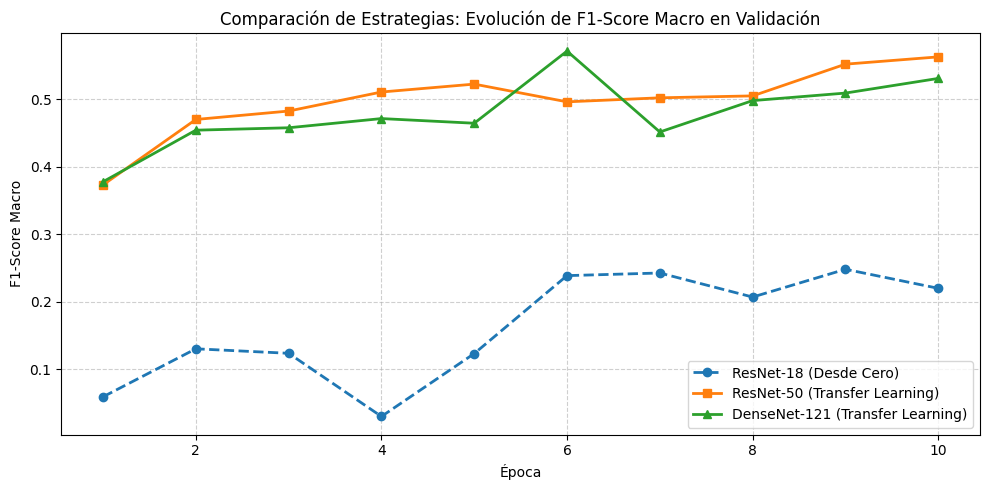

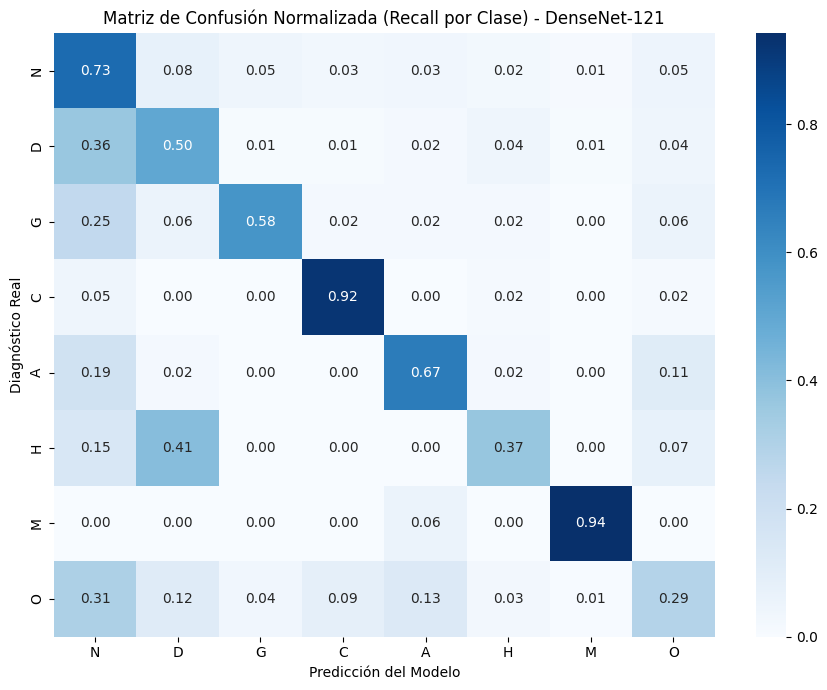


--- AUDITORÍA DE SESGOS Y EQUIDAD CLÍNICA ---
Metadatos EXIF de cámara detectados en muestra: 0 (Dataset anonimizado).

Desempeño por Sexo Biológico:
 - Female (n=591): F1-Macro = 0.5946 | Recall-Macro = 0.6612
 - Male   (n=688): F1-Macro = 0.5471 | Recall-Macro = 0.5914

Desempeño por Grupo Etario:
 - <= 50 años   (n=297): F1-Macro = 0.5346 | Recall-Macro = 0.6493
 - 51 - 65 años (n=654): F1-Macro = 0.5484 | Recall-Macro = 0.5882
 - > 65 años    (n=328): F1-Macro = 0.6198 | Recall-Macro = 0.7038


In [2]:
# ==============================================================================
# CUADERNO 05: COMPARACIÓN DE ITERACIONES, MATRIZ DE CONFUSIÓN Y ANÁLISIS DE SESGO
# ==============================================================================
from google.colab import drive
import os
import shutil
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image
from sklearn.metrics import confusion_matrix, f1_score, recall_score, classification_report

# 1. Montar Drive y cargar archivos guardados
drive.mount('/content/drive')
BASE_DIR = '/content/drive/MyDrive/BaseDatos'
PROCESSED_CSV_PATH = os.path.join(BASE_DIR, 'df_procesado_folds.csv')
PREPROC_DIR = os.path.join(BASE_DIR, 'preprocessed_images')
MODELOS_DIR = os.path.join(BASE_DIR, 'modelos_entrenados')

df_clean = pd.read_csv(PROCESSED_CSV_PATH)
LOCAL_IMG_DIR = '/content/imagenes_locales'
if not os.path.exists(LOCAL_IMG_DIR):
    shutil.copytree(PREPROC_DIR, LOCAL_IMG_DIR)

clases_ordenadas = ['N', 'D', 'G', 'C', 'A', 'H', 'M', 'O']
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 2. Gráfico comparativo de curvas de evolución (si existen los historiales)
modelos_hist = [
    ('hist_resnet18_scratch.json', 'ResNet-18 (Desde Cero)', '--', 'o'),
    ('hist_resnet50_tl.json', 'ResNet-50 (Transfer Learning)', '-', 's'),
    ('hist_densenet121_tl.json', 'DenseNet-121 (Transfer Learning)', '-', '^')
]

plt.figure(figsize=(10, 5))
for archivo, etiqueta, estilo, marcador in modelos_hist:
    ruta_h = os.path.join(MODELOS_DIR, archivo)
    if os.path.exists(ruta_h):
        with open(ruta_h, 'r') as f:
            h = json.load(f)
        plt.plot(range(1, len(h['val_f1_macro']) + 1), h['val_f1_macro'],
                 linestyle=estilo, marker=marcador, label=etiqueta, linewidth=2)
plt.title('Comparación de Estrategias: Evolución de F1-Score Macro en Validación')
plt.xlabel('Época')
plt.ylabel('F1-Score Macro')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# 3. Cargar mejor modelo (DenseNet-121) y evaluar sobre Fold 0
val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class ODIRDataset(Dataset):
    def __init__(self, dataframe, img_dir, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.img_dir = img_dir
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(os.path.join(self.img_dir, row['filename'])).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(row['label_idx'], dtype=torch.long)

val_df = df_clean[df_clean['fold'] == 0].reset_index(drop=True)
val_loader = DataLoader(ODIRDataset(val_df, LOCAL_IMG_DIR, val_transforms), batch_size=32, shuffle=False)

model_best = models.densenet121(weights=None)
model_best.classifier = nn.Linear(model_best.classifier.in_features, 8)
model_best.load_state_dict(torch.load(os.path.join(MODELOS_DIR, 'mejor_densenet121_tl.pth'), map_location=device))
model_best = model_best.to(device)
model_best.eval()

y_pred_dense, y_true_dense = [], []
with torch.no_grad():
    for inputs, labels in val_loader:
        outputs = model_best(inputs.to(device))
        y_pred_dense.extend(torch.max(outputs, 1)[1].cpu().numpy())
        y_true_dense.extend(labels.numpy())

# 4. Matriz de Confusión Normalizada
cm = confusion_matrix(y_true_dense, y_pred_dense, normalize='true')
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', xticklabels=clases_ordenadas, yticklabels=clases_ordenadas)
plt.title('Matriz de Confusión Normalizada (Recall por Clase) - DenseNet-121')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Diagnóstico Real')
plt.tight_layout()
plt.show()

# 5. Auditoría de Sesgos (Metadatos EXIF de cámara y Demografía)
print("\n--- AUDITORÍA DE SESGOS Y EQUIDAD CLÍNICA ---")
orig_train_dir = os.path.join(BASE_DIR, 'ODIR-5K', 'ODIR-5K', 'Training Images')
muestras_exif = 0
if os.path.exists(orig_train_dir):
    for f_img in os.listdir(orig_train_dir)[:50]:
        img = Image.open(os.path.join(orig_train_dir, f_img))
        if img._getexif():
            muestras_exif += 1
print(f"Metadatos EXIF de cámara detectados en muestra: {muestras_exif} (Dataset anonimizado).")

val_df['pred'] = y_pred_dense
val_df['real'] = y_true_dense
val_df['grupo_edad'] = pd.cut(val_df['Patient Age'], bins=[0, 50, 65, 120], labels=['<= 50 años', '51 - 65 años', '> 65 años'])

print("\nDesempeño por Sexo Biológico:")
for sexo, grupo in val_df.groupby('Patient Sex'):
    print(f" - {sexo:6s} (n={len(grupo)}): F1-Macro = {f1_score(grupo['real'], grupo['pred'], average='macro', zero_division=0):.4f} | "
          f"Recall-Macro = {recall_score(grupo['real'], grupo['pred'], average='macro', zero_division=0):.4f}")

print("\nDesempeño por Grupo Etario:")
for edad, grupo in val_df.groupby('grupo_edad', observed=False):
    print(f" - {edad:12s} (n={len(grupo)}): F1-Macro = {f1_score(grupo['real'], grupo['pred'], average='macro', zero_division=0):.4f} | "
          f"Recall-Macro = {recall_score(grupo['real'], grupo['pred'], average='macro', zero_division=0):.4f}")